# Taller 5 — Regresión Logística sobre el dataset Wine
**Puntos 5, 6 y 7:** primer modelo, verificación de resultados y depuración (validación cruzada).

**Decisiones de diseño (buenas prácticas):**
- Se reproduce *exactamente* el split de `data.ipynb` (30 % de prueba, `random_state=42`, estratificado), para que los resultados sean comparables con los de los compañeros.
- La estandarización va **dentro de un `Pipeline`**: en cada fold de la validación cruzada el `StandardScaler` aprende solo de los datos de entrenamiento de ese fold (sin fuga de información). Por eso aquí se parte de los datos crudos y no de los CSV ya estandarizados.
- Los hiperparámetros y el conjunto de variables se eligen **solo con el conjunto de entrenamiento** (validación cruzada). El conjunto de prueba se usa una única vez, al final.
- Como las clases están desbalanceadas (59/71/48), la métrica de selección es **F1 macro** y no solo accuracy.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict,
                                     cross_val_score, learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
clases = ['Cultivar 0', 'Cultivar 1', 'Cultivar 2']

variables_fuertes = ['flavanoids', 'proline', 'od280/od315_of_diluted_wines',
                     'alcohol', 'color_intensity', 'hue', 'total_phenols']
variables_debiles = [c for c in X.columns if c not in variables_fuertes]
conjuntos = {'completo': list(X.columns), 'fuertes': variables_fuertes, 'debiles': variables_debiles}

# Mismo split que data.ipynb (30 % prueba, estratificado)
idx_train, idx_test = train_test_split(X.index, test_size=0.30, random_state=SEED, stratify=y)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Distribución train:', y_train.value_counts().sort_index().tolist(),
      '| test:', y_test.value_counts().sort_index().tolist())

Train: (124, 13) | Test: (54, 13)
Distribución train: [41, 50, 33] | test: [18, 21, 15]


# 5) Elaboración del primer modelo (Regresión Logística)

## 5.1 Multinomial vs One-vs-Rest
El enunciado pide configurar el modelo para multiclase. Comparamos las dos estrategias con la misma validación cruzada (5 folds × 3 repeticiones, solo sobre entrenamiento):
- **Multinomial (softmax):** un solo modelo que estima $P(y=k\mid x)=\dfrac{e^{w_k^\top x+b_k}}{\sum_j e^{w_j^\top x+b_j}}$ minimizando la entropía cruzada conjunta. Es el comportamiento por defecto de `LogisticRegression` en scikit-learn moderno.
- **One-vs-Rest:** 3 clasificadores binarios independientes (clase $k$ vs. el resto) y se escoge la clase con mayor probabilidad.

In [2]:
cv_comp = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def pipe(modelo):
    return Pipeline([('scaler', StandardScaler()), ('clf', modelo)])

estrategias = {
    'Multinomial': pipe(LogisticRegression(max_iter=5000)),
    'One-vs-Rest': pipe(OneVsRestClassifier(LogisticRegression(max_iter=5000))),
}
filas = []
for nombre, p in estrategias.items():
    r = cross_validate(p, X_train, y_train, cv=cv_comp, scoring=['accuracy', 'f1_macro'])
    filas.append({'Estrategia': nombre,
                  'Accuracy CV': r['test_accuracy'].mean(), 'Std acc': r['test_accuracy'].std(),
                  'F1 macro CV': r['test_f1_macro'].mean(), 'Std F1': r['test_f1_macro'].std()})
pd.DataFrame(filas).round(4)

,Estrategia,Accuracy CV,Std acc,F1 macro CV,Std F1
0,Multinomial,0.984,0.0196,0.9834,0.0203
1,One-vs-Rest,0.984,0.0196,0.9834,0.0203


## 5.2 Selección de variables
En el punto 3 el equipo separó las variables en *fuertes* (mayor F de ANOVA) y *débiles*. Aquí lo comprobamos con el modelo: comparamos los tres conjuntos con validación cruzada **sobre entrenamiento** (no sobre prueba, para no «mirar» el test al decidir).

In [3]:
filas = []
for nombre, cols in conjuntos.items():
    r = cross_validate(pipe(LogisticRegression(max_iter=5000)), X_train[cols], y_train,
                       cv=cv_comp, scoring=['accuracy', 'f1_macro'])
    filas.append({'Conjunto': nombre, 'n_vars': len(cols),
                  'Accuracy CV': r['test_accuracy'].mean(), 'F1 macro CV': r['test_f1_macro'].mean(),
                  'Std F1': r['test_f1_macro'].std()})
tabla_vars = pd.DataFrame(filas).round(4)
tabla_vars

,Conjunto,n_vars,Accuracy CV,F1 macro CV,Std F1
0,completo,13,0.9840,0.9834,0.0203
1,fuertes,7,0.9597,0.9600,0.0418
2,debiles,6,0.7910,0.7905,0.0734


## 5.3 Ajuste del hiperparámetro de regularización $C$
$C=1/\lambda$ controla la regularización L2: valores pequeños → modelo más simple (más sesgo, menos varianza); valores grandes → modelo más flexible. Se busca con `GridSearchCV` (5×3 folds, solo entrenamiento). También se prueba `class_weight='balanced'` por el desbalance de clases.

In [4]:
param_grid = {'clf__C': np.logspace(-3, 2, 21), 'clf__class_weight': [None, 'balanced']}
busqueda = GridSearchCV(pipe(LogisticRegression(max_iter=5000)), param_grid,
                        cv=cv_comp, scoring='f1_macro', n_jobs=-1, refit=True)
busqueda.fit(X_train[conjuntos['completo']], y_train)

print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'F1 macro CV (train): {busqueda.best_score_:.4f}')
modelo = busqueda.best_estimator_      # ya reajustado con todo el entrenamiento

Mejores hiperparámetros: {'clf__C': np.float64(0.31622776601683794), 'clf__class_weight': None}
F1 macro CV (train): 0.9834


### Primer modelo final: coeficientes

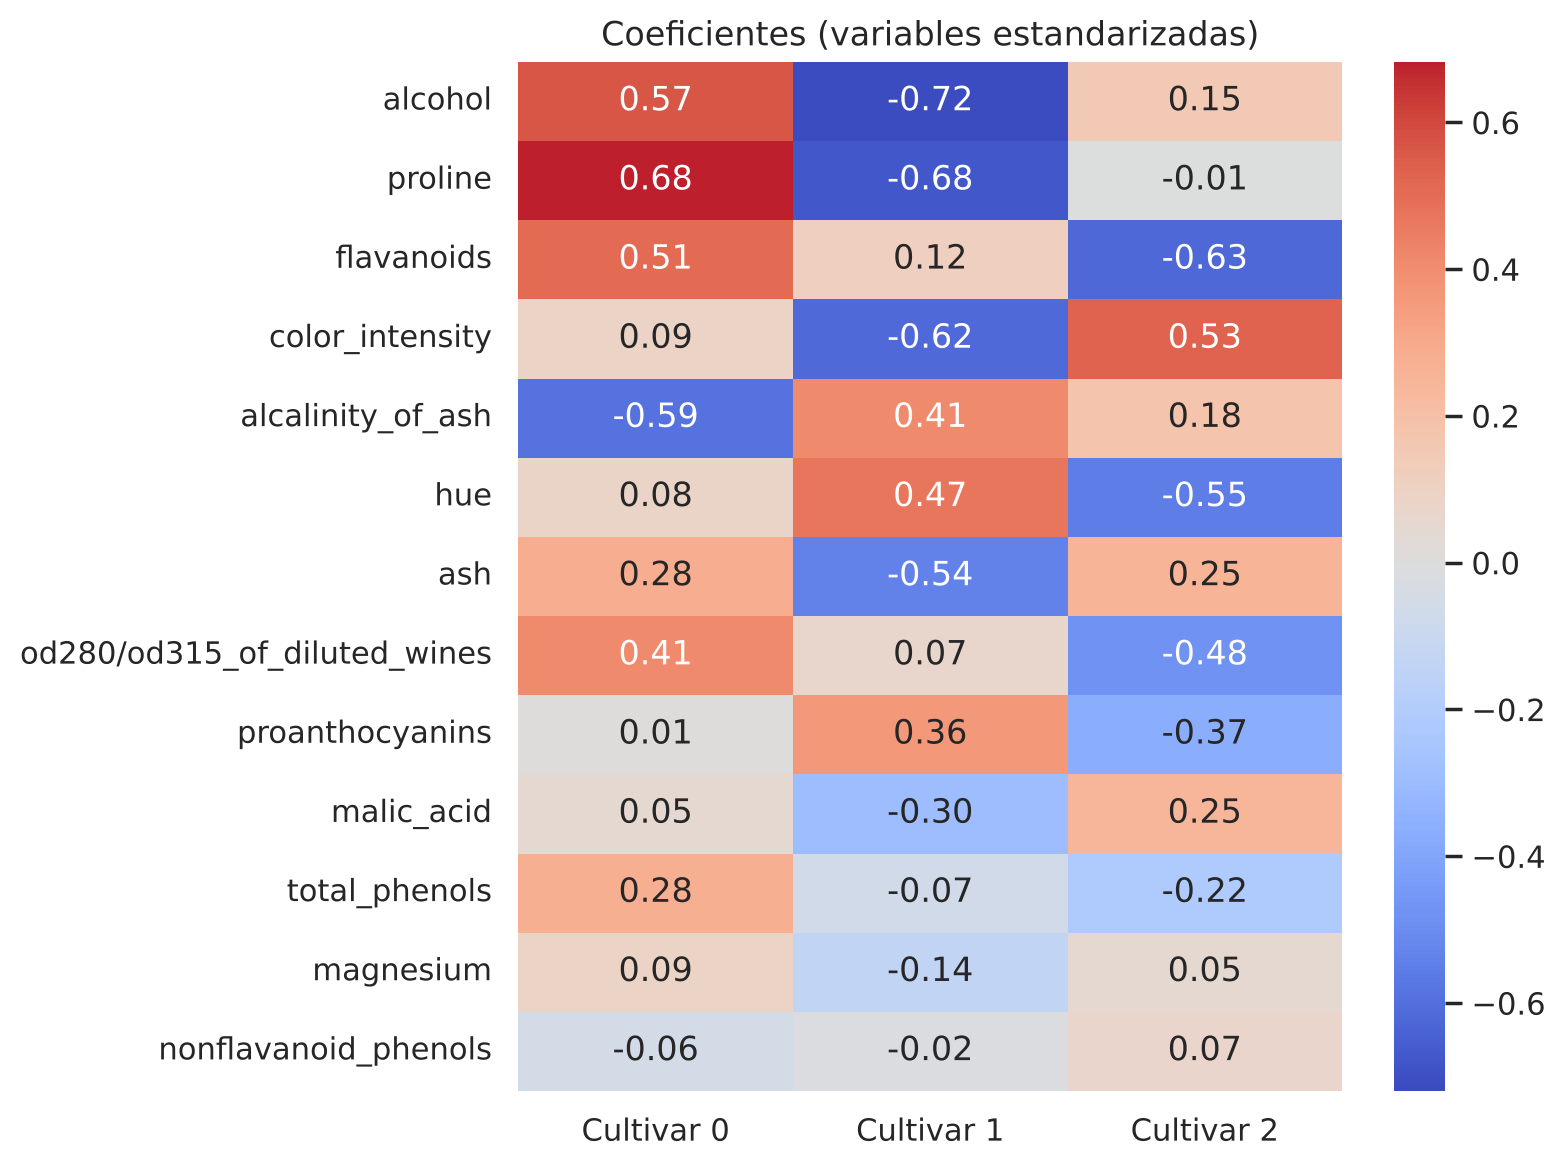

In [5]:
coefs = pd.DataFrame(modelo.named_steps['clf'].coef_.T, index=conjuntos['completo'], columns=clases)
coefs['|coef| máx'] = coefs.abs().max(axis=1)
coefs = coefs.sort_values('|coef| máx', ascending=False).drop(columns='|coef| máx')
plt.figure(figsize=(8, 6))
sns.heatmap(coefs, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Coeficientes (variables estandarizadas)')
plt.tight_layout(); plt.show()

Como las variables están estandarizadas, los coeficientes son comparables: los de mayor magnitud (p. ej. `proline`, `flavanoids`, `color_intensity`, `alcohol`) son los que más pesan en la decisión, lo cual coincide con el análisis ANOVA/boxplots del punto 3.

# 6) Verificación de resultados
Es la **única** vez que se usa el conjunto de prueba (54 muestras).

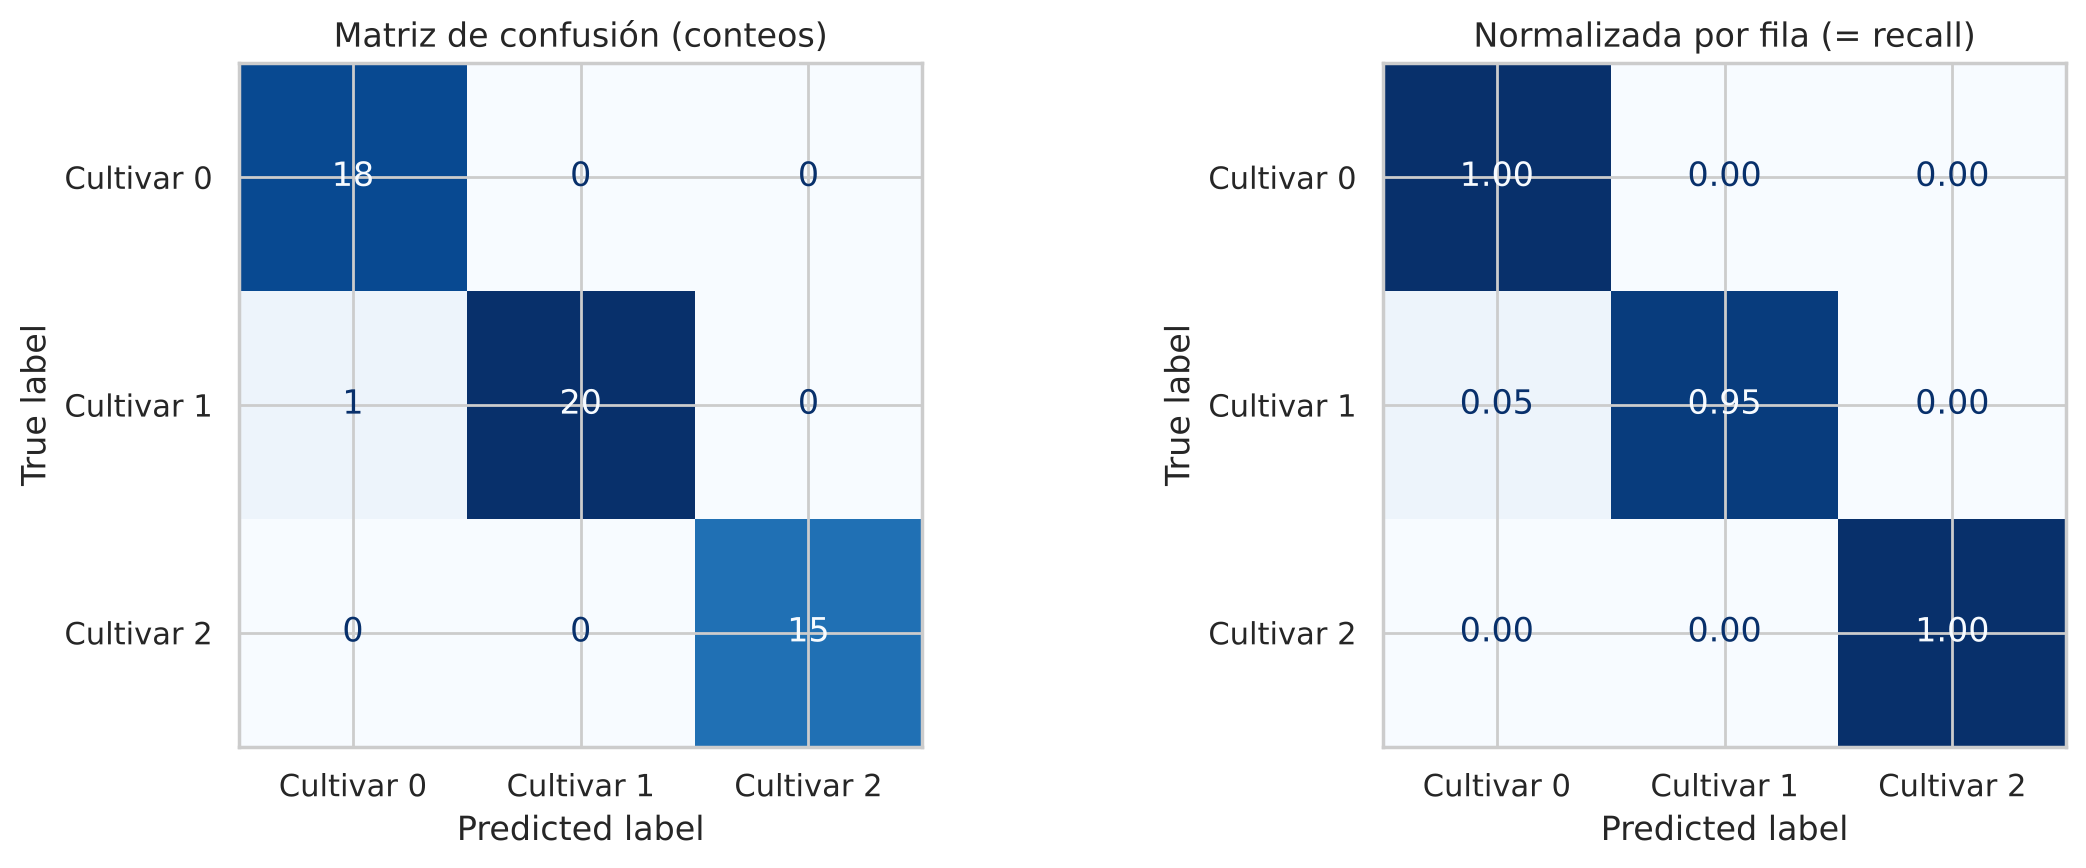

Accuracy en prueba: 0.9815


In [6]:
y_pred = modelo.predict(X_test[conjuntos['completo']])
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=clases).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Matriz de confusión (conteos)')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize='true'), display_labels=clases
                       ).plot(ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
ax[1].set_title('Normalizada por fila (= recall)')
plt.tight_layout(); plt.show()
print(f'Accuracy en prueba: {accuracy_score(y_test, y_pred):.4f}')

## 6.1 Métricas calculadas a partir de la matriz
Para cada clase $k$: $\text{Precisión}_k=\dfrac{TP_k}{TP_k+FP_k}$ (columna), $\text{Recall}_k=\dfrac{TP_k}{TP_k+FN_k}$ (fila), $F1_k=\dfrac{2\,P_kR_k}{P_k+R_k}$. Se calculan a mano y se verifican contra `scikit-learn`.

In [7]:
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
soporte = cm.sum(axis=1)

metricas = pd.DataFrame({'TP': TP, 'FP': FP, 'FN': FN, 'Precisión': precision,
                         'Recall': recall, 'F1': f1, 'Soporte': soporte}, index=clases)
metricas.loc['Macro avg'] = [np.nan]*3 + [precision.mean(), recall.mean(), f1.mean(), soporte.sum()]
metricas.loc['Weighted avg'] = [np.nan]*3 + [np.average(precision, weights=soporte),
                                              np.average(recall, weights=soporte),
                                              np.average(f1, weights=soporte), soporte.sum()]
display(metricas.round(4))

# Verificación contra sklearn
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred)
assert np.allclose(p, precision) and np.allclose(r, recall) and np.allclose(f, f1)
print(classification_report(y_test, y_pred, target_names=clases, digits=4))

,TP,FP,FN,Precisión,Recall,F1,Soporte
Cultivar 0,18.0,1.0,0.0,0.9474,1.0000,0.9730,18.0
Cultivar 1,20.0,0.0,1.0,1.0000,0.9524,0.9756,21.0
Cultivar 2,15.0,0.0,0.0,1.0000,1.0000,1.0000,15.0
Macro avg,NaN,NaN,NaN,0.9825,0.9841,0.9829,54.0
Weighted avg,NaN,NaN,NaN,0.9825,0.9815,0.9815,54.0


              precision    recall  f1-score   support

  Cultivar 0     0.9474    1.0000    0.9730        18
  Cultivar 1     1.0000    0.9524    0.9756        21
  Cultivar 2     1.0000    1.0000    1.0000        15

    accuracy                         0.9815        54
   macro avg     0.9825    0.9841    0.9829        54
weighted avg     0.9825    0.9815    0.9815        54



## 6.2 Estabilidad de la estimación
Con solo 54 muestras de prueba, un error cambia el accuracy en ≈1.9 puntos. Para tener una estimación más estable de la matriz de confusión, se calcula también con predicciones *out-of-fold* (10 folds) sobre **todo** el dataset (cada muestra se predice con un modelo que no la vio).

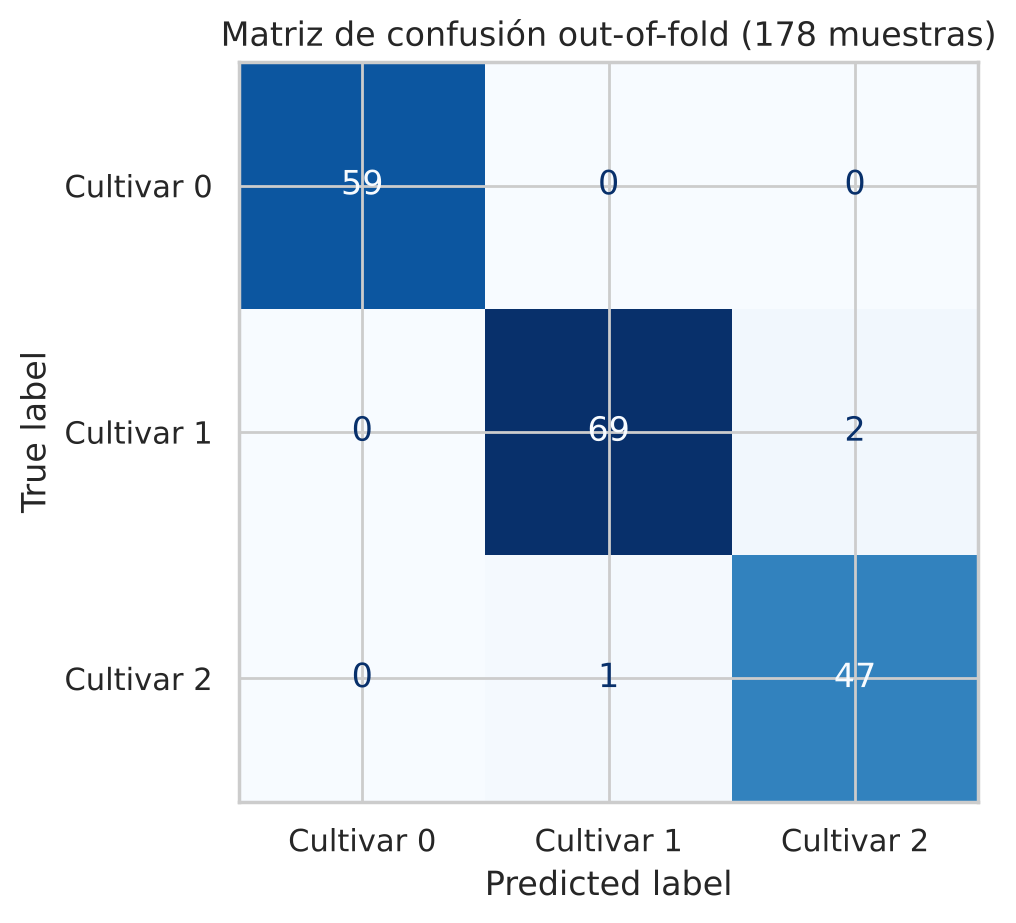

              precision    recall  f1-score   support

  Cultivar 0     1.0000    1.0000    1.0000        59
  Cultivar 1     0.9857    0.9718    0.9787        71
  Cultivar 2     0.9592    0.9792    0.9691        48

    accuracy                         0.9831       178
   macro avg     0.9816    0.9837    0.9826       178
weighted avg     0.9833    0.9831    0.9832       178



In [8]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
y_oof = cross_val_predict(modelo, X[conjuntos['completo']], y, cv=cv10)
cm_oof = confusion_matrix(y, y_oof)
ConfusionMatrixDisplay(cm_oof, display_labels=clases).plot(cmap='Blues', colorbar=False)
plt.title('Matriz de confusión out-of-fold (178 muestras)'); plt.show()
print(classification_report(y, y_oof, target_names=clases, digits=4))

## 6.3 Impacto comercial y métrica a priorizar
**Impacto comercial.** Clasificar mal un vino del cultivar de alta calidad tiene dos costos distintos:
- **Falso negativo** (un vino premium etiquetado como otro cultivar): se vende como producto de menor categoría, con menor precio, y se pierde el margen y la reputación de la denominación. Es el error más costoso porque el valor perdido es directo y difícil de recuperar una vez embotellado/etiquetado.
- **Falso positivo** (un vino de otro cultivar etiquetado como premium): riesgo de fraude/reclamos, pérdida de confianza del cliente y posibles sanciones por mal etiquetado.

**Métrica a priorizar.** Para el cultivar de alta calidad se prioriza el **Recall** de esa clase (no dejar escapar ningún vino premium), vigilando que la **Precisión** no caiga demasiado; el **F1** de la clase resume ese equilibrio, y el **F1 macro** es la métrica global adecuada por el desbalance 59/71/48. El accuracy por sí solo se descarta porque oculta errores en las clases minoritarias. El dataset no indica cuál cultivar es el «premium», así que la tabla de abajo muestra el recall y la precisión de cada uno para aplicar el criterio al que corresponda. En prueba, el modelo tiene recall 1.00 en los cultivares 0 y 2 y 0.95 en el 1 (un solo error: un vino del cultivar 1 clasificado como 0).

In [9]:
# Recall y precisión por clase: prueba vs. out-of-fold
recall_oof = np.diag(cm_oof) / cm_oof.sum(axis=1)
prec_oof = np.diag(cm_oof) / cm_oof.sum(axis=0)
pd.DataFrame({'Recall (prueba)': recall, 'Recall (out-of-fold)': recall_oof,
              'Precisión (prueba)': precision, 'Precisión (out-of-fold)': prec_oof}, index=clases).round(4)

,Recall (prueba),Recall (out-of-fold),Precisión (prueba),Precisión (out-of-fold)
Cultivar 0,1.0000,1.0000,0.9474,1.0000
Cultivar 1,0.9524,0.9718,1.0000,0.9857
Cultivar 2,1.0000,0.9792,1.0000,0.9592


# 7) Depuración del modelo: validación cruzada y descarte de sobreajuste
Un modelo está sobreajustado cuando rinde mucho mejor en entrenamiento que en datos no vistos. Se revisa con cuatro evidencias complementarias:
1. CV de 10 folds (repetida) con `return_train_score`: brecha entre train y validación.
2. Curva de validación sobre $C$: ¿el rendimiento de validación colapsa cuando el modelo gana flexibilidad?
3. Curva de aprendizaje: ¿convergen las curvas de train y validación?
4. CV anidada: estimación del rendimiento **sin** el sesgo optimista de haber ajustado $C$ con los mismos folds.

,Train,Validación,Std validación,Brecha (train − val)
Accuracy,1.0,0.9863,0.0243,0.0137
F1 macro,1.0,0.9862,0.0246,0.0138


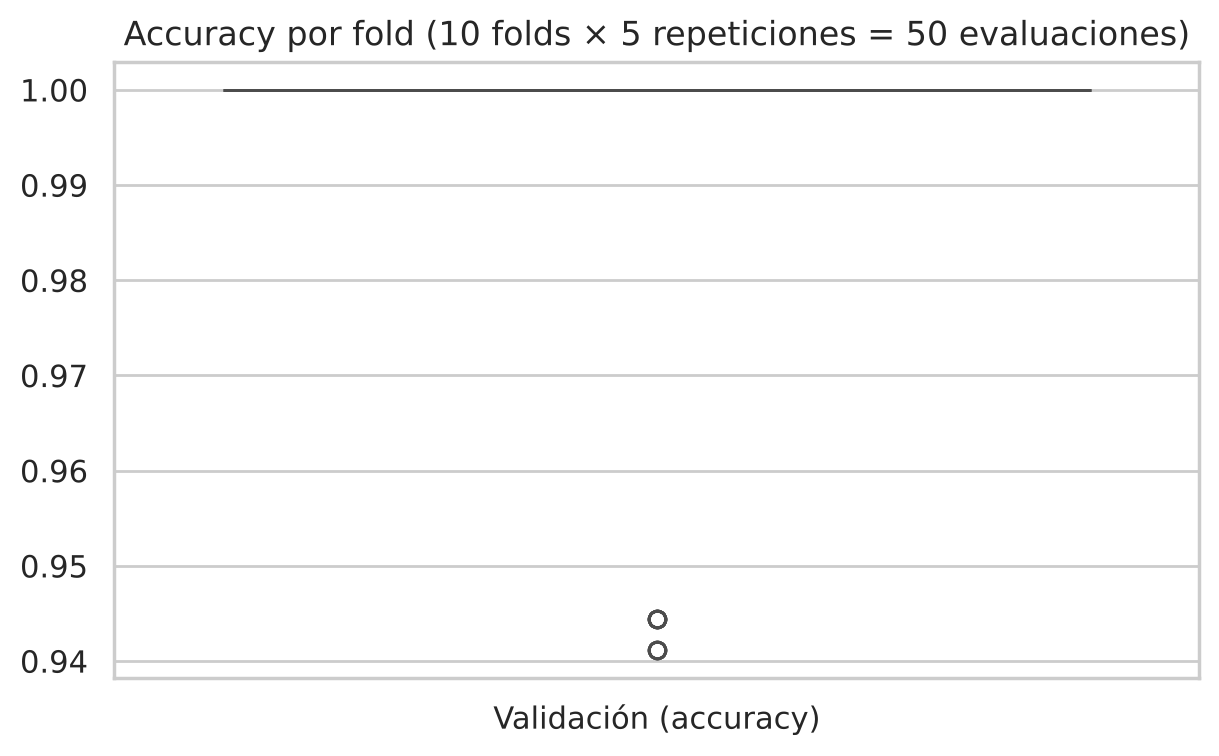

In [10]:
cv_rep = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=SEED)
res = cross_validate(modelo, X[conjuntos['completo']], y, cv=cv_rep,
                     scoring=['accuracy', 'f1_macro'], return_train_score=True)
resumen = pd.DataFrame({
    'Train': [res['train_accuracy'].mean(), res['train_f1_macro'].mean()],
    'Validación': [res['test_accuracy'].mean(), res['test_f1_macro'].mean()],
    'Std validación': [res['test_accuracy'].std(), res['test_f1_macro'].std()],
}, index=['Accuracy', 'F1 macro'])
resumen['Brecha (train − val)'] = resumen['Train'] - resumen['Validación']
display(resumen.round(4))

plt.figure(figsize=(7, 4))
sns.boxplot(data=pd.DataFrame({'Validación (accuracy)': res['test_accuracy']}), color='steelblue')
plt.title('Accuracy por fold (10 folds × 5 repeticiones = 50 evaluaciones)')
plt.show()

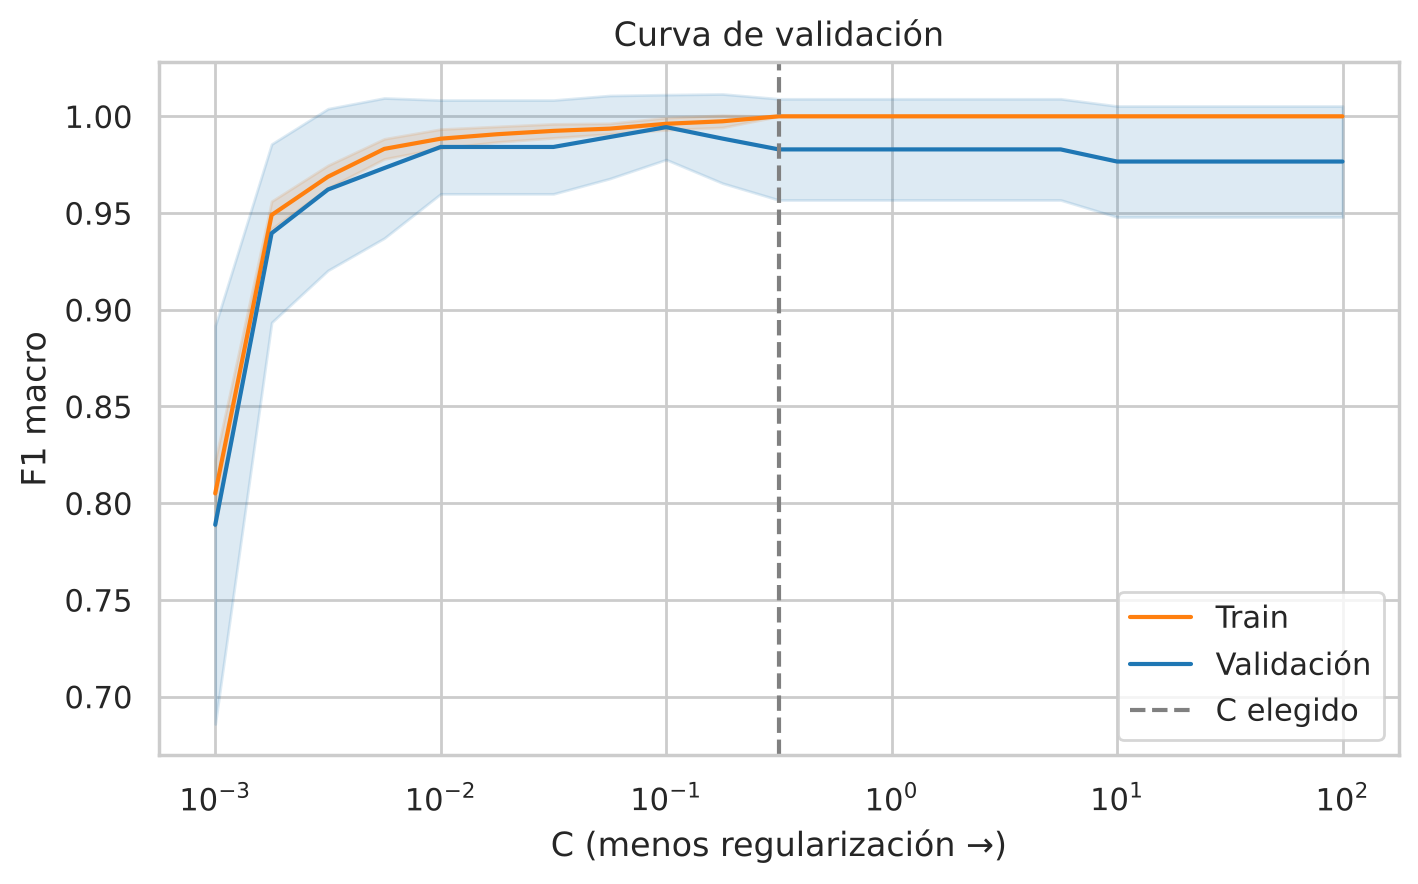

In [11]:
rangoC = np.logspace(-3, 2, 21)
modelo_vc = pipe(LogisticRegression(max_iter=5000, class_weight=modelo.named_steps['clf'].class_weight))
tr, va = validation_curve(modelo_vc, X[conjuntos['completo']], y, param_name='clf__C',
                          param_range=rangoC, cv=cv10, scoring='f1_macro', n_jobs=-1)
plt.figure(figsize=(8, 4.5))
for s, lab, c in [(tr, 'Train', 'tab:orange'), (va, 'Validación', 'tab:blue')]:
    plt.semilogx(rangoC, s.mean(1), label=lab, color=c)
    plt.fill_between(rangoC, s.mean(1)-s.std(1), s.mean(1)+s.std(1), alpha=.15, color=c)
plt.axvline(modelo.named_steps['clf'].C, ls='--', c='gray', label='C elegido')
plt.xlabel('C (menos regularización →)'); plt.ylabel('F1 macro'); plt.legend()
plt.title('Curva de validación'); plt.show()

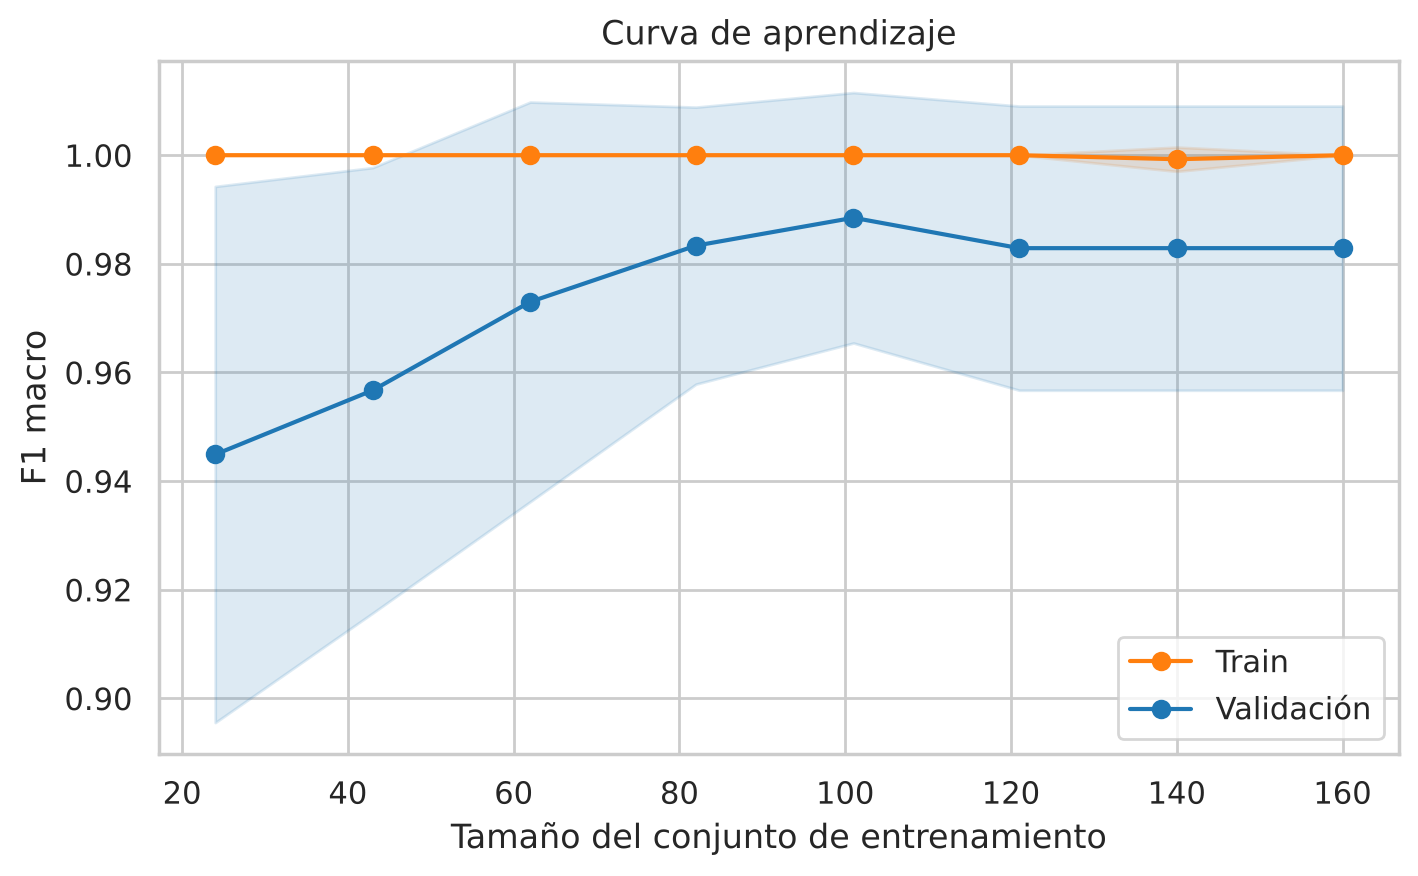

In [12]:
sizes, tr, va = learning_curve(modelo, X[conjuntos['completo']], y, cv=cv10, scoring='f1_macro',
                               train_sizes=np.linspace(0.15, 1.0, 8), n_jobs=-1, shuffle=True, random_state=SEED)
plt.figure(figsize=(8, 4.5))
for s, lab, c in [(tr, 'Train', 'tab:orange'), (va, 'Validación', 'tab:blue')]:
    plt.plot(sizes, s.mean(1), 'o-', label=lab, color=c)
    plt.fill_between(sizes, s.mean(1)-s.std(1), s.mean(1)+s.std(1), alpha=.15, color=c)
plt.xlabel('Tamaño del conjunto de entrenamiento'); plt.ylabel('F1 macro'); plt.legend()
plt.title('Curva de aprendizaje'); plt.show()

In [13]:
# CV anidada: bucle externo evalúa, bucle interno elige C y class_weight
interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
externo = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED + 1)
gs_interno = GridSearchCV(pipe(LogisticRegression(max_iter=5000)), param_grid,
                          cv=interno, scoring='f1_macro', n_jobs=-1)
anidada = cross_val_score(gs_interno, X[conjuntos['completo']], y, cv=externo,
                          scoring='f1_macro', n_jobs=-1)
print(f'F1 macro CV anidada: {anidada.mean():.4f} ± {anidada.std():.4f}  (n={len(anidada)} evaluaciones)')

F1 macro CV anidada: 0.9780 ± 0.0150  (n=15 evaluaciones)


## Conclusión sobre sobreajuste
- **Brecha train–validación pequeña:** en la CV repetida (10 folds × 5) el modelo obtiene ≈1.00 en entrenamiento y ≈0.986 en validación (brecha ≈1.4 puntos). Que el entrenamiento llegue a 1.00 es esperable con 13 variables muy informativas y clases casi separables linealmente; lo relevante es que el rendimiento en datos no vistos se mantiene casi igual de alto y estable (desviación ≈0.02).
- **Curva de validación:** al aumentar $C$ (menos regularización) el rendimiento de validación no se desploma; solo cae levemente (≈0.99 → ≈0.98), lo que confirma que el modelo es poco sensible a la regularización y que el $C$ elegido no está en una zona de sobreajuste.
- **Curva de aprendizaje:** la validación sube y se estabiliza en ≈0.98 desde unas 80 muestras de entrenamiento; la brecha con el entrenamiento es pequeña (≈2 puntos) y no crece. Más datos darían, como mucho, una mejora marginal.
- **CV anidada:** el F1 macro estimado sin sesgo de selección es ≈0.978, muy cercano al ≈0.983 de la CV simple, así que ajustar $C$ no infló el resultado de forma importante.
- **Prueba (54 muestras):** accuracy 0.9815, coherente con lo anterior.

**Conclusión:** no hay evidencia de sobreajuste. El modelo generaliza bien (≈98 % de accuracy / F1 macro). Se recomienda reportar el rango de la CV (≈0.98 ± 0.02) y no solo el valor puntual de prueba, porque con 178 muestras un único error mueve el accuracy casi 2 puntos.

# Modelo final
Se guarda el pipeline (escalador + regresión logística) para reutilizarlo en la comparación con KNN (punto 8).

In [14]:
import joblib
joblib.dump(modelo, 'modelo_regresion_logistica.joblib')
print(modelo)

Pipeline(steps=[('scaler', StandardScaler()),
                ('clf',
                 LogisticRegression(C=np.float64(0.31622776601683794),
                                    max_iter=5000))])
